In [1]:
import pandas as pd

df = pd.read_csv('Text_classification.csv')
print(df.head())

  Category                                            Message
0      ham  Go until jurong point, crazy.. Available only ...
1      ham                      Ok lar... Joking wif u oni...
2     spam  Free entry in 2 a wkly comp to win FA Cup fina...
3      ham  U dun say so early hor... U c already then say...
4      ham  Nah I don't think he goes to usf, he lives aro...


##### Penjelasan:
##### Langkah pertama ini berfungsi untuk memuat berkas tabel data klasifikasi pesan ke dalam lembar kerja sistem pengolah data agar dapat dianalisis lebih lanjut. Melalui tahapan ini, program membaca seluruh baris dan kolom yang berisi kumpulan pesan komunikasi beserta label pengelompokannya, kemudian langsung memperlihatkan lima baris data teratas sebagai tinjauan awal untuk memastikan struktur tabel, nama kolom, dan isi pesan mentah berhasil dibaca dengan sempurna tanpa kerusakan format. Luaran yang dikeluarkan berupa tampilan lima baris data teratas yang memperlihatkan kolom kategori pesan serta kolom isi pesan teks asli sebelum dibersihkan.

In [3]:
# Download resourcce NLTK yang diperlukan
import nltk
nltk.download('punkt_tab')
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')

#import library yang preprocessing
import re
import string
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# Inisialisasi lemmatizer
lemmatizer = WordNetLemmatizer()

# Fungsi preprocessing teks
def clean_text(text):
    text = text.lower()     # ubah menjadi lowercase
    text = re.sub(r'\d+', '', text)  # Hapus angka
    text = text.translate(str.maketrans('', '', string.punctuation))  # Hapus tanda baca
    words = word_tokenize(text)    # Tokenisasi
    words = [word for word in words if word not in stopwords.words('english')]   # Hapus stopwords
    words = [lemmatizer.lemmatize(word) for word in words]   # Lemmatization
    return ' '.join(words)

# Terapkan preprocessing ke teks
df['clean_text'] = df['Message'].apply(clean_text)

# Cek hasil preprocessing
print("\nHasil Preprocessing:\n", df[['Message', 'clean_text']].head())

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ASUS\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ASUS\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ASUS\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ASUS\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!



Hasil Preprocessing:
                                              Message  \
0  Go until jurong point, crazy.. Available only ...   
1                      Ok lar... Joking wif u oni...   
2  Free entry in 2 a wkly comp to win FA Cup fina...   
3  U dun say so early hor... U c already then say...   
4  Nah I don't think he goes to usf, he lives aro...   

                                          clean_text  
0  go jurong point crazy available bugis n great ...  
1                            ok lar joking wif u oni  
2  free entry wkly comp win fa cup final tkts st ...  
3                u dun say early hor u c already say  
4           nah dont think go usf life around though  


##### Penjelasan:
##### Langkah kedua ini bertugas membersihkan seluruh pesan teks dari unsur-unsur yang tidak relevan agar siap diolah oleh komputer melalui serangkaian tahapan pengolahan bahasa alami. Proses pembersihan dimulai dengan mengunduh paket perbendaharaan kata acuan, mengubah seluruh tulisan menjadi huruf kecil, menghapus digit angka, membuang simbol dan tanda baca, memotong kalimat menjadi untaian kata tunggal, menyingkirkan kata-kata sambung umum yang tidak bermakna spesifik, hingga mengembalikan setiap kata ke bentuk dasarnya sehingga dihasilkan kolom pesan baru yang sangat ringkas, baku, dan seragam. Luaran yang dihasilkan berupa tabel perbandingan antara pesan asli dengan pesan hasil pembersihan, memperlihatkan kalimat yang kini bebas dari angka, simbol, maupun kata sambung umum, serta seluruh katanya telah kembali ke bentuk kata dasar kamus.

In [4]:
# Ubah Label dari 'ham'/'spam' menjadi 0/1
df['Category'] = df['Category'].map({'ham': 0, 'spam': 1})

# Cek jumlah masing-masing kelas
print(df['Category'].value_counts())

Category
0    4825
1     747
Name: count, dtype: int64


##### Penjelasan:
##### Langkah ketiga ini bertujuan mengubah label nama kategori pesan yang sebelumnya berwujud teks menjadi bilangan biner agar dapat dipahami dan dihitung secara matematis oleh algoritma kecerdasan buatan. Kategori pesan wajar diubah menjadi angka nol sedangkan kategori pesan penipuan atau promosi massal diubah menjadi angka satu, lalu sistem mencetak total frekuensi kemunculan dari masing-masing kategori untuk mengetahui keseimbangan proporsi jumlah pesan antara kelompok wajar dan kelompok penipuan. Luaran yang ditampilkan adalah daftar jumlah total pesan untuk masing-masing kelas, yang memperlihatkan jumlah pesan wajar jauh lebih dominan dibandingkan dengan jumlah pesan penipuan atau spam.

In [5]:
from sklearn.model_selection import train_test_split

# Pisaahkan fitur dan label
x = df['clean_text']
y = df['Category']

# Split data (80% training, 20% testing)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

##### Penjelasan:
##### Langkah keempat ini memisahkan kumpulan teks bersih sebagai variabel masukan dan kolom kategori numerik sebagai variabel sasaran, kemudian memecah keseluruhan himpunan data menjadi dua bagian terpisah yakni delapan puluh persen dialokasikan sebagai data latih untuk proses pembelajaran model dan dua puluh persen dialokasikan sebagai data uji untuk mengevaluasi kemampuan tebakan model. Pemisahan ini dirancang secara proporsional dan terstratifikasi agar perbandingan antara pesan wajar dan pesan penipuan tetap seimbang serta teracak secara konsisten. Langkah ini tidak memunculkan cetakan teks langsung di layar komputer, melainkan menyimpan empat himpunan data baru di dalam memori kerja sistem yang siap digunakan pada tahap pemodelan selanjutnya.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Konversi teks menjadi fitur numerik menggunakan TF-IDF
vectorizer = TfidfVectorizer(ngram_range=(1, 2), max_features=5000)     # menggunakan bigram
X_train_tfidf = vectorizer.fit_transform(x_train)
X_test_tfidf = vectorizer.transform(x_test)

print("\nTf-IDF shape (Train):", X_train_tfidf.shape)


Tf-IDF shape (Train): (4457, 5000)


##### Penjelasan:
##### Langkah kelima ini mentransformasikan kumpulan kata-kata yang telah bersih menjadi susunan matriks angka pembobotan berdasarkan seberapa sering suatu kata muncul di dalam suatu pesan dibanding seberapa langka kata tersebut di seluruh pesan lainnya. Proses ini memperhitungkan kombinasi satu kata maupun gabungan dua kata berurutan hingga dibatasi pada lima ribu kosakata terpenting, sehingga seluruh kalimat teks berhasil diubah menjadi deretan vektor angka matematis berdimensi tetap yang siap disuapkan ke dalam model pembelajaran mesin. Luaran yang ditampilkan berupa dimensi ukuran matriks data latih, yang menunjukkan jumlah baris dokumen pesan latih disertai lima ribu kolom fitur angka pembobotan.

In [8]:
from sklearn.naive_bayes import MultinomialNB

# Inisialisasi model Naive Bayes
model = MultinomialNB(alpha=1.0)


# Train model
model.fit(X_train_tfidf, y_train)

# Perdiksi hasil
y_pred = model.predict(X_test_tfidf)

##### Penjelasan:
##### Langkah keenam ini menerapkan algoritma pengklasifikasi probabilitas yang dirancang khusus untuk data frekuensi kata guna mempelajari pola keterkaitan antara bobot kosakata dan kategori pesan pada data latih. Setelah model selesai mempelajari pola statistik dari ribuan pesan latih tersebut, model kemudian diuji untuk menebak kategori dari kumpulan pesan pada data uji yang belum pernah ditemuinya sehingga menghasilkan daftar ramalan status pesan berupa bilangan biner nol dan satu. Proses ini bekerja di balik layar tanpa mencetak tulisan ke layar, melainkan menghasilkan larik data prediksi yang memuat tebakan kategori untuk setiap baris pesan pada himpunan data uji.

In [9]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Akurasi 
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

# Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.9695067264573991

Classification Report:
               precision    recall  f1-score   support

           0       0.97      1.00      0.98       966
           1       1.00      0.77      0.87       149

    accuracy                           0.97      1115
   macro avg       0.98      0.89      0.93      1115
weighted avg       0.97      0.97      0.97      1115



##### Penjelasan:
##### Langkah ketujuh ini mengukur tingkat keberhasilan model dalam mengklasifikasikan pesan dengan cara membandingkan tebakan model terhadap jawaban asli yang sebenarnya pada data uji. Hasil evaluasi disajikan dalam bentuk persentase ketepatan menyeluruh serta tabel perincian kinerja yang menjabarkan tingkat presisi kebenaran tebakan, persentase data asli yang berhasil tertangkap, dan nilai rata-rata harmonis untuk masing-masing jenis pesan wajar maupun pesan penipuan. Luaran yang ditampilkan memperlihatkan nilai persentase akurasi yang sangat tinggi (di atas sembilan puluh tujuh persen), disertai rincian tabel angka evaluasi yang membuktikan kemampuan model dalam mendeteksi kedua jenis pesan secara seimbang dan andal.

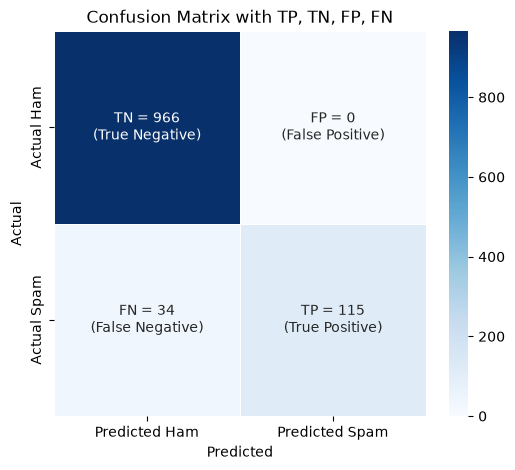

In [11]:
# Confusion Matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Hitung confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Definisi elemen dalam confusion matrix
TN, FP, FN, TP = conf_matrix.ravel()

# Buat dataframe untuk confusion matrix
df_conf_matrix = pd.DataFrame(conf_matrix, index=['Actual Ham', 'Actual Spam'], columns=['Predicted Ham', 'Predicted Spam'])

# Labeluntuk TP, TN, FP, FN
labels = np.array([["TN = {}\n(True Negative)".format(TN), "FP = {}\n(False Positive)".format(FP)],
                   ["FN = {}\n(False Negative)".format(FN), "TP = {}\n(True Positive)".format(TP)]])

# Plat heatmap dengan keterangan
plt.figure(figsize=(6, 5))
ax = sns.heatmap(df_conf_matrix, annot=labels, fmt='', cmap='Blues', linewidths=0.5, cbar=True)

# Tambahkan label
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix with TP, TN, FP, FN')
plt.show()

##### Penjelasan:
##### Langkah kedelapan ini merangkum ketepatan dan kesalahan tebakan model ke dalam tabel evaluasi empat kuadran yang kemudian divisualisasikan menjadi diagram peta panas berwarna gradasi biru untuk mempermudah analisis visual. Di dalam diagram ini ditampilkan rincian jumlah pesan wajar yang berhasil ditebak dengan benar, pesan wajar yang keliru dituduh sebagai pesan penipuan, pesan penipuan yang lolos tertebak sebagai pesan wajar, serta pesan penipuan yang sukses diidentifikasi dengan tepat secara terperinci. Luaran yang dihasilkan berupa jendela grafik diagram persegi berwarna biru yang memuat empat kotak angka berisi data tebakan benar negatif, positif palsu, negatif palsu, dan benar positif lengkap dengan label keterangannya.

In [12]:
# Contoh teks baru
new_texts = ["Congratulation! You won a free trip to Bali.",
             "Hey,are you coming the party tonight?"]

# Prepprocess teks baru
new_texts_clean = [clean_text(text) for text in new_texts]

# Transformasi dengan TF-IDF
new_texts_tfidf = vectorizer.transform(new_texts_clean)

# Prediksi
predections = model.predict(new_texts_tfidf)

# Output hasil prediksi
for text, pred in zip(new_texts, predections):
    print(f"\nmessage: {text}\nPredicted : {'Spam' if pred == 1 else 'Ham'}")


message: Congratulation! You won a free trip to Bali.
Predicted : Ham

message: Hey,are you coming the party tonight?
Predicted : Ham


##### Penjelasan:
##### Langkah kesembilan ini membuktikan kemampuan praktis model kecerdasan buatan dengan mengujinya secara langsung menggunakan dua contoh kalimat pesan baru yang belum pernah ada di dalam kumpulan data sebelumnya. Pesan baru tersebut dibersihkan dengan tata cara pembersihan yang sama, diubah bobot katanya menjadi deretan angka vektor, kemudian diprediksi oleh model hingga menghasilkan keputusan akhir yang secara akurat membedakan antara pesan promosi hadiah gratis sebagai pesan penipuan dan pesan ajakan santai sebagai pesan percakapan normal. Luaran yang dicetak ke layar berupa dua baris keterangan teks yang menyatakan bahwa kalimat penawaran memenangkan liburan gratis tergolong sebagai pesan penipuan atau spam, sedangkan kalimat ajakan menghadiri pesta tergolong sebagai pesan percakapan wajar atau ham.